# Model Training

This is the main part of the project. The first part will be creating baseline model using static embedding and Logistic Regression. Then I switch to contextual embedding with pretrained model like sentence-transformer and other ML models KNN and QDA

## 1. Base Model

The base model will be Word2Vec + Logistic Regression. However, for the simplicity of the project, I will use a pretrained Word2Vec model to embed instead of training a brand new one due to the limitation in available text.

The pretrained Word2Vec is glove-wiki-gigaword-50: trained on wikipedia texts, lightweight and good for English

In [33]:
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
sys.path.append(str(ROOT_DIR))

from custom_scripts import Processing
from sklearn.linear_model import LogisticRegression
import gensim.downloader as api
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    confusion_matrix
)

def get_sentence_embedding(text, model):
    words = text.lower().split()

    vectors = [model[word] for word in words if word in model]

    if not vectors:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


label_encoder = LabelEncoder()


processor = Processing.DataProcessor("../Data")
train = processor.get_train_df()
test = processor.get_test_df()

model = api.load('glove-wiki-gigaword-50')  # Load the GloVe model

In [34]:
X_train = np.array([
    get_sentence_embedding(text, model)
    for text in train["text"]
])

X_test = np.array([
    get_sentence_embedding(text, model)
    for text in test["text"]
])

y_train = label_encoder.fit_transform(train["intent"])
y_test = label_encoder.transform(test["intent"])


In Logistic Regression, $C$ controls the strength of regularization:
- Small $C$: stronger regularization, simpler model, potentially underfits.
- Large $C$: weaker regularization, more flexibility, potentially overfits.

In [35]:
grid_search = GridSearchCV(LogisticRegression(max_iter=1000), param_grid={'C': [0.1, 1, 5, 10, 20]}, cv=5)

grid_search.fit(X_train, y_train)

best_base = grid_search.best_params_

error_rates = 1- grid_search.cv_results_['mean_test_score']

Text(0, 0.5, 'Error Rate')

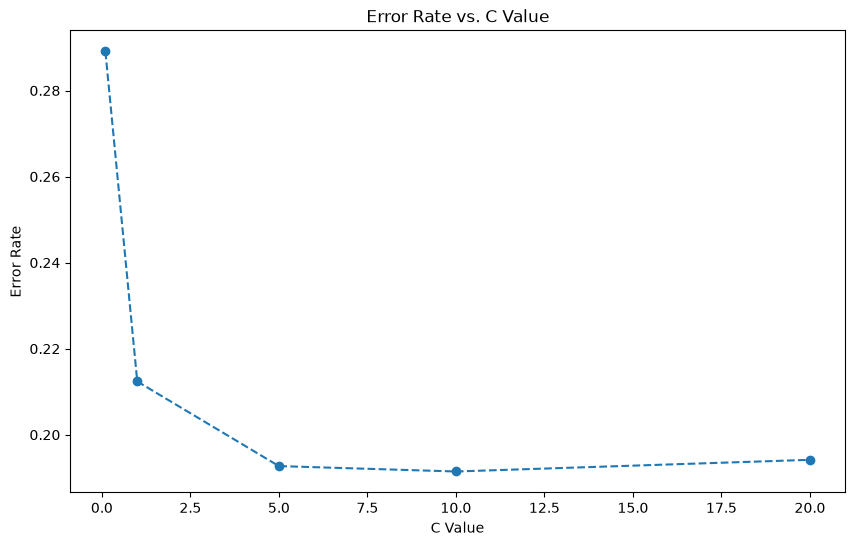

In [36]:
plt.figure(figsize=(10, 6))
plt.plot([0.1, 1, 5, 10, 20], error_rates, marker='o', linestyle='--')
plt.title('Error Rate vs. C Value')
plt.xlabel('C Value')
plt.ylabel('Error Rate')

In [37]:
test_error = 1 - grid_search.score(X_test, y_test)
print(f"Test Error: {test_error}")

Test Error: 0.31327272727272726


Using GloVe and Logistic Regression (C=10) evaluated using $Error Rate = 1 - Accuracy$, Test error is 31%, which is not great

Accuracy:  0.6867
F1-Macro:  0.7420
Recall:    0.8085
Precision: 0.6991


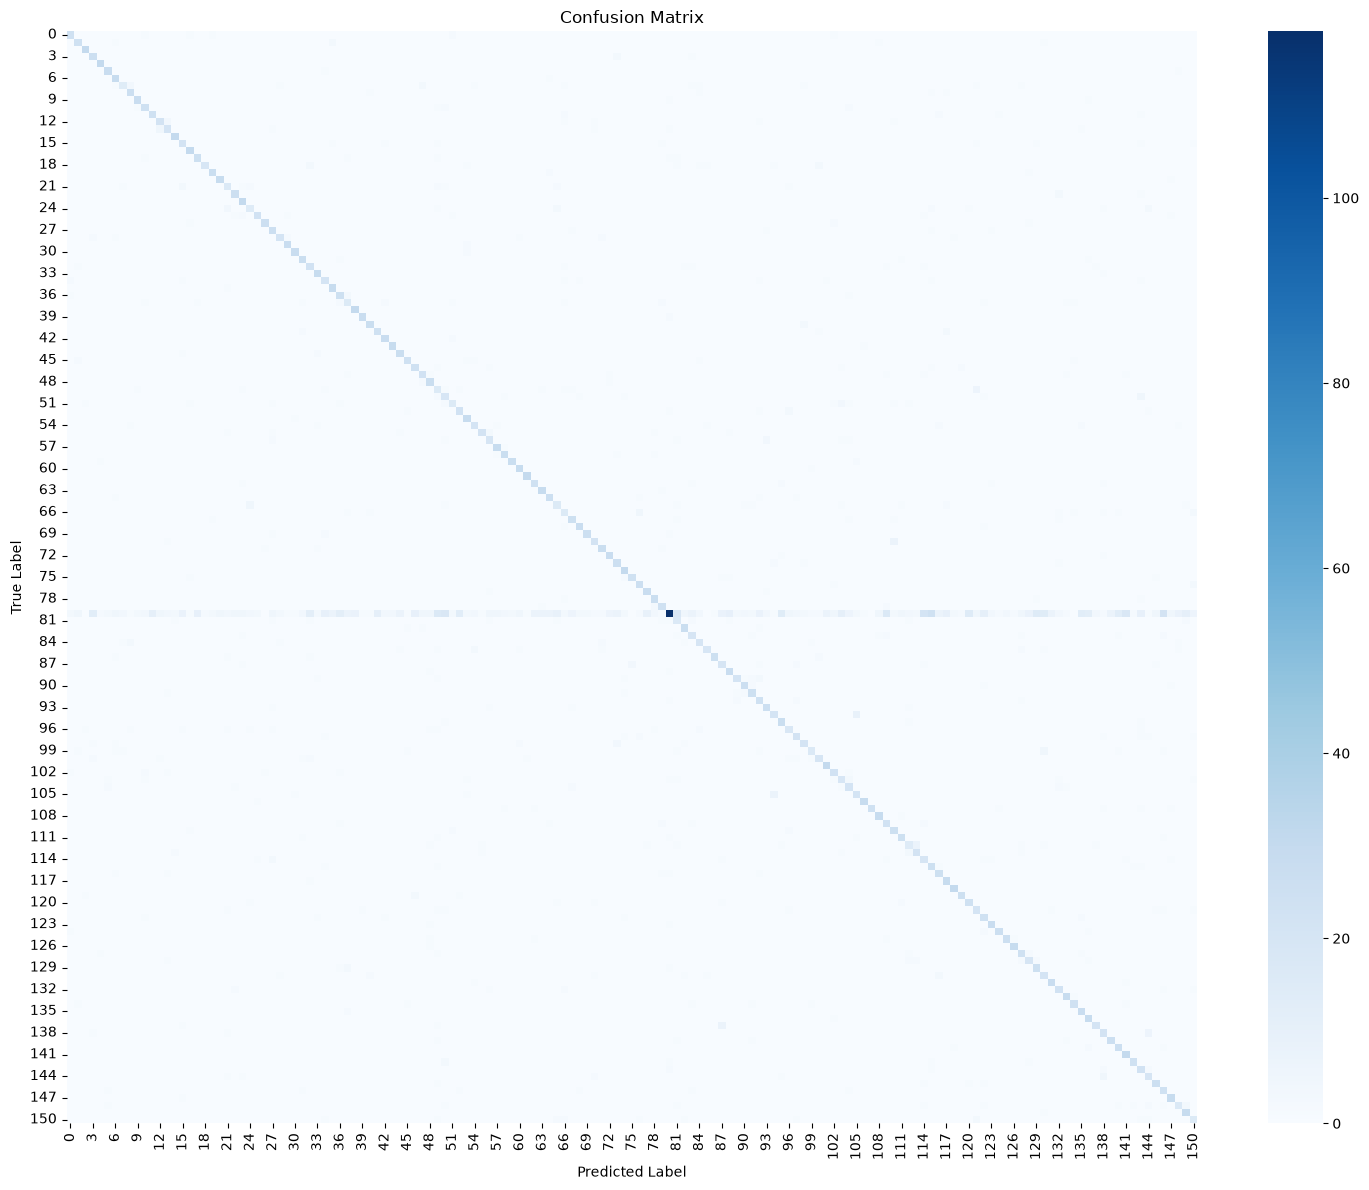

In [38]:
def evaluate_model(model, X, y, figsize=(15, 12)):
    y_pred = model.predict(X)

    print(f"Accuracy:  {accuracy_score(y, y_pred):.4f}")
    print(f"F1-Macro:  {f1_score(y, y_pred, average='macro'):.4f}")
    print(f"Recall:    {recall_score(y, y_pred, average='macro'):.4f}")
    print(f"Precision: {precision_score(y, y_pred, average='macro'):.4f}")

    cm = confusion_matrix(y, y_pred)

    plt.figure(figsize=figsize)
    sns.heatmap(cm, cmap="Blues", annot=False)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

evaluate_model(grid_search, X_test, y_test)

The metrics gives a very promising result for a base model with Accuracy:  0.6867, F1-Macro:  0.7420, Recall: 0.8085 , Precision: 0.6991. Using the confusion matrix, we also see the model predict correctly most of the time (diagonal line). Hence, this is a good start for our intent classification task. 